In [4]:
#All the imports
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.stats import norm
from scipy.stats import kurtosis
import fifpy

plt.rcParams.update({
    'font.size': 15,
    'axes.titlesize': 15,
    'axes.labelsize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'figure.titlesize': 15
})

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.fields import compute_radial_spectrum, partial_x_fft, partial_y_fft
from shared.filtering import iterative_filtering1D, iterative_filtering3D
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("quality_checks", "SpectrumAnimation")

In [5]:
def compute_spectra_at_time(base_path, t, dx, dy):
    File_Bx = f"{base_path}/Bx_ApJ_t{t}.h5"
    File_By = f"{base_path}/By_ApJ_t{t}.h5"
    File_Bz = f"{base_path}/Bz_ApJ_t{t}.h5"
    File_Dn = f"{base_path}/Dn1_ApJ_t{t}.h5"

    File_Ux = f"{base_path}/Ux1_ApJ_t{t}.h5"
    File_Uy = f"{base_path}/Uy1_ApJ_t{t}.h5"
    File_Uz = f"{base_path}/Uz1_ApJ_t{t}.h5"

    with h5py.File(File_Bx, 'r') as fBx, \
         h5py.File(File_By, 'r') as fBy, \
         h5py.File(File_Bz, 'r') as fBz:

        data_Bx = fBx['DS1'][:].T
        data_By = fBy['DS1'][:].T
        data_Bz = fBz['DS1'][:].T

    with h5py.File(File_Dn, 'r') as fDn:
        data_Dn = fDn['DS1'][:].T

    with h5py.File(File_Ux, 'r') as fUx, \
         h5py.File(File_Uy, 'r') as fUy, \
         h5py.File(File_Uz, 'r') as fUz:

        data_Ux = fUx['DS1'][:].T
        data_Uy = fUy['DS1'][:].T
        data_Uz = fUz['DS1'][:].T

    data_Ux = data_Ux/data_Dn
    data_Uy = data_Uy/data_Dn
    data_Uz = data_Uz/data_Dn
    
    # Spectra
    spectrum_Bx = compute_radial_spectrum(data_Bx, dx, dy)
    spectrum_By = compute_radial_spectrum(data_By, dx, dy)
    spectrum_Bz = compute_radial_spectrum(data_Bz, dx, dy)

    spectrum_Ux = compute_radial_spectrum(data_Ux, dx, dy)
    spectrum_Uy = compute_radial_spectrum(data_Uy, dx, dy)
    spectrum_Uz = compute_radial_spectrum(data_Uz, dx, dy)

    spectrum_B = spectrum_Bx.sp + spectrum_By.sp + spectrum_Bz.sp
    spectrum_U = spectrum_Ux.sp + spectrum_Uy.sp + spectrum_Uz.sp

    kk = spectrum_Bx.kk  # assume same grid

    return kk, spectrum_B, spectrum_U

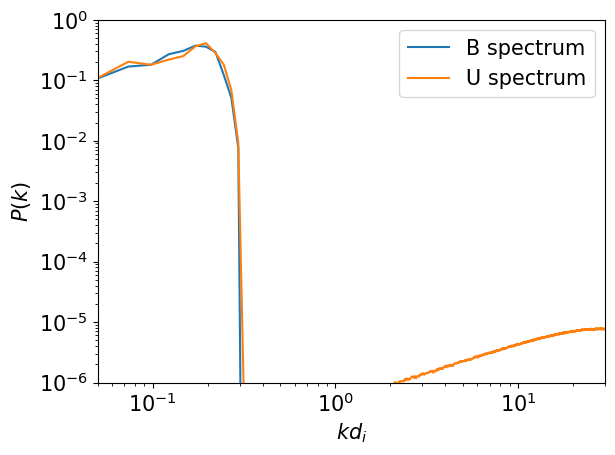

In [3]:
# List of simulation directories

dx = 0.0625
dy = 0.0625

base_path = f"{DATA_ROOT}/beta_p_1/beta_e_1"

kk, spec_B, spec_U = compute_spectra_at_time(base_path, 0, dx, dy)

#Plot

plt.loglog(kk, spec_B, label="B spectrum")
plt.loglog(kk, spec_U, label="U spectrum")

plt.xlabel(r"$kd_i$")
plt.ylabel(r"$P(k)$")
plt.xlim(5e-2, 30)
plt.ylim(1e-6, 1)

plt.legend()  # <-- this is the key line

plt.tight_layout()
plt.savefig(RESULTS / "JU_Spectrum", dpi=300)
plt.show()

Computing spectra for 301 snapshots across 128 workers ...
t=82: done
t=81: done
t=37: done
t=60: done
t=108: done
t=109: done
t=117: done
t=94: done
t=42: done
t=33: done
t=68: done
t=35: done
t=121: done
t=111: done
t=36: done
t=87: done
t=88: done
t=24: done
t=76: done
t=49: done
t=64: done
t=70: done
t=74: done
t=118: done
t=124: done
t=120: done
t=41: done
t=77: done
t=100: done
t=54: done
t=106: done
t=65: done
t=18: done
t=116: done
t=48: done
t=92: done
t=55: done
t=115: done
t=67: done
t=16: done
t=97: done
t=91: done
t=9: done
t=0: done
t=43: done
t=71: done
t=126: done
t=10: done
t=3: done
t=32: done
t=93: done
t=26: done
t=113: done
t=53: done
t=72: done
t=29: done
t=52: done
t=20: done
t=17: done
t=21: done
t=45: done
t=56: done
t=30: done
t=96: done
t=107: done
t=28: done
t=75: done
t=105: done
t=61: done
t=78: done
t=22: done
t=27: done
t=103: done
t=62: done
t=86: done
t=69: done
t=50: done
t=1: done
t=46: done
t=80: done
t=104: done
t=101: done
t=84: done
t=44: done
t=

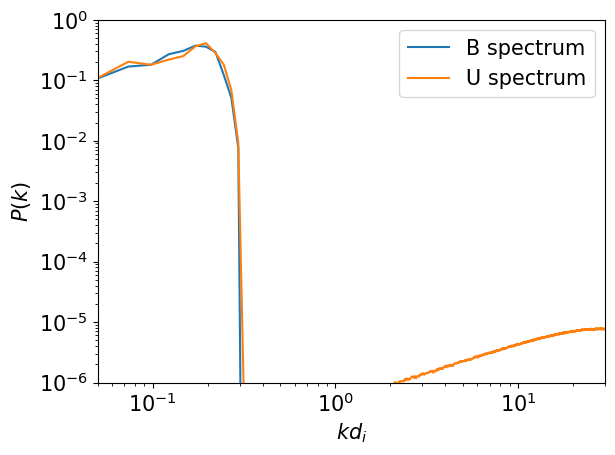

In [6]:
# ================================================================
#  Animation of the B and U spectra, t = 0 .. 150
#  The plot is kept exactly as your static figure; only the spectra
#  lines update each frame. Per-snapshot spectra are computed in parallel.
#
#  Needs from your session: compute_spectra_at_time
# ================================================================

import os
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

# ---------- settings ----------
dx = dy   = 0.0625
base_path = f"{DATA_ROOT}/beta_p_1/beta_e_1"
times     = range(0, 301)               # frames (t = 0 .. 150)
out_file  = str(RESULTS / "JU_Spectrum.mp4")
fps       = 12

# each worker loads 7 full fields, so memory ~ N_WORKERS * ~1 GB.
# lower this if you hit memory limits; raise it if you have headroom.
N_WORKERS = 128
THREADS_PER_WORKER = 1


def _init_worker(n):
    if threadpool_limits is not None:
        threadpool_limits(n)


def _worker(t):
    kk, spec_B, spec_U = compute_spectra_at_time(base_path, t, dx, dy)
    return t, kk, spec_B, spec_U


# ---------- compute every frame (parallel over time) ----------
frames = []                              # each: (t, kk, spec_B, spec_U)
task_times = list(times)

if N_WORKERS == 1:
    for t in task_times:
        try:
            frames.append(_worker(t)); print(f"t={t}: done", flush=True)
        except FileNotFoundError:
            print(f"t={t}: missing file, skipped", flush=True)
else:
    ctx = mp.get_context("fork")
    print(f"Computing spectra for {len(task_times)} snapshots across {N_WORKERS} workers ...", flush=True)
    with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx,
                             initializer=_init_worker, initargs=(THREADS_PER_WORKER,)) as ex:
        futs = {ex.submit(_worker, t): t for t in task_times}
        for fut in as_completed(futs):
            t = futs[fut]
            try:
                frames.append(fut.result()); print(f"t={t}: done", flush=True)
            except FileNotFoundError:
                print(f"t={t}: missing file, skipped", flush=True)

if not frames:
    raise SystemExit("No frames computed (check paths / times).")
frames.sort(key=lambda f: f[0])          # time order


# ---------- Plot  (unchanged from your static figure) ----------
fig = plt.figure()
lineB, = plt.loglog([], [], label="B spectrum")
lineU, = plt.loglog([], [], label="U spectrum")
plt.xlabel(r"$kd_i$")
plt.ylabel(r"$P(k)$")
plt.xlim(5e-2, 30)
plt.ylim(1e-6, 1)
plt.legend()
plt.tight_layout()


def update(i):
    t, kk, spec_B, spec_U = frames[i]
    lineB.set_data(kk, spec_B)
    lineU.set_data(kk, spec_U)
    return lineB, lineU


anim = FuncAnimation(fig, update, frames=len(frames), interval=1000 / fps)
anim.save(out_file, writer="ffmpeg", fps=fps)
print(f"saved {out_file}")